# Lesson 4 — Real data: the Osborne copper-gold mine

**The data:** an airborne magnetic survey flown by the Queensland Government in 1990, ~80 m above the ground, on east–west lines ~250 m apart
(via the `ensaio` package; original data © Geoscience Australia, CC-BY). We use a 2.4 × 2.8 km window over the Osborne anomaly.

**The ground truth we can check against** (published, not used for fitting):
- Osborne was discovered under **25–40 m of younger sedimentary cover**; the main ore zone lies right beneath it.
- Ore sits in **magnetite-rich ironstones**: "two dominant mineralised bodies" in the western domain, ~1100 m and ~700 m long, steeply dipping,
  carrying copper-gold "along 1.3 km of strike" (Porter GeoConsultancy summary).
- History: 97 holes drilled into the magnetic anomaly 1985–87 found nothing economic; the discovery hole came in 1989.
  Published work (Anderson & Logan 1992; Bjork et al. 2021) says the anomaly is **offset from the ore** because the ironstones are so magnetic that
  they partly cancel their own magnetisation (*self-demagnetisation*) — something our physics leaves out.

**Plan**
1. Look at the data. Split it: 8 flight lines to learn from, 3 **held-out lines** to test on.
2. Upgrade the physics from a sphere to a **rectangular block** — and verify the formula.
3. **Model 1 — one block.** Train a flow (Recipe B), look at the pictures, check everything.
4. **Model 2 — two blocks.** Same again.
5. Compare: fit to the training lines vs. honesty on the held-out lines.
6. Compare with the published geology.

Runs in ~15 minutes the first time (uses the GPU for the physics if available); later runs reuse the saved flows.

In [1]:
import sys, time, math, inspect
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.interpolate import griddata
import ensaio
import normflows as nf
import geomag as gm
import osborne as ob

torch.set_default_dtype(torch.float64)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("physics runs on:", DEV)

physics runs on: cuda


## 1. The data

447 training readings on 8 lines, 171 held-out readings on 3 lines
anomaly range: -717 … 5598 nT


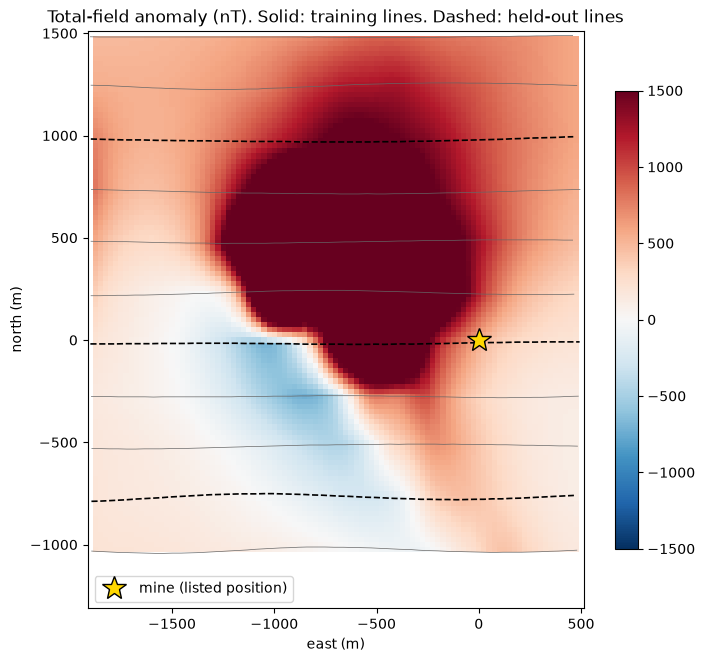

In [2]:
data_path = ensaio.fetch_osborne_magnetic(version=1)
w = ob.load_window(data_path)                      # every 5th reading (~40 m apart along each line)
w_full = ob.load_window(data_path, every=1)        # every reading, only for drawing the map
train = w[w.flight_line.isin(ob.TRAIN_LINES)]
hold = w[w.flight_line.isin(ob.HOLDOUT_LINES)]
print(f"{len(train)} training readings on {train.flight_line.nunique()} lines, {len(hold)} held-out readings on {hold.flight_line.nunique()} lines")
print(f"anomaly range: {w.total_field_anomaly_nt.min():.0f} … {w.total_field_anomaly_nt.max():.0f} nT")

T = lambda s: torch.tensor(np.asarray(s, dtype=float))
tr_xyz = (T(train.north), T(train.east), T(train.z)); tr_y = T(train.total_field_anomaly_nt)
ho_xyz = (T(hold.north), T(hold.east), T(hold.z)); ho_y = T(hold.total_field_anomaly_nt)

gn, ge = np.meshgrid(np.arange(-1300, 1501, 25), np.arange(-1900, 501, 25), indexing="ij")
grid_map = griddata((w_full.north, w_full.east), w_full.total_field_anomaly_nt, (gn, ge), method="linear")

def base_map(ax, title=""):
    im = ax.pcolormesh(ge, gn, grid_map, cmap="RdBu_r", vmin=-1500, vmax=1500, shading="auto")
    for ln, g in w.groupby("flight_line"):
        held = ln in ob.HOLDOUT_LINES
        ax.plot(g.east, g.north, "--" if held else "-", color="k" if held else "0.4", lw=1.2 if held else 0.5)
    ax.plot(0, 0, "*", color="gold", mec="k", ms=18, label="mine (listed position)")
    ax.set_aspect("equal"); ax.set_xlabel("east (m)"); ax.set_ylabel("north (m)"); ax.set_title(title)
    return im

fig, ax = plt.subplots(figsize=(8, 8.5))
im = base_map(ax, "Total-field anomaly (nT). Solid: training lines. Dashed: held-out lines")
plt.colorbar(im, ax=ax, shrink=0.7); ax.legend(loc="lower left"); plt.show()

The red/blue pair is the classic southern-hemisphere signature we met in Lesson 2: a big high on the north side, a low on the south side.
Note the gold star: the anomaly's centre is ~0.5–1 km **west** of the mine's listed position. Keep that in mind.

## 2. Physics upgrade: a magnetised rectangular block

The ironstones are sheets, not balls. So the new building block is a vertical-sided **rectangular block** with 8 numbers:
centre (north, east), top depth, bottom depth, length, width, strike direction, susceptibility. Its anomaly has an exact formula (Blakely 1995).
Earth's field at Osborne in 1990 (IGRF): **52,086 nT, inclination −53.4°, declination 6.7°**.

**Verify before trusting:** a block is just a pile of tiny magnets. Chop one into 216,000 tiny cubes, add up their fields one by one (slow but obviously right),
and compare with the formula.

In [3]:
def brute_force_block(obs_n, obs_e, obs_z, xc, yc, top, bot, L, W, strike, chi, n=60):
    i, d = math.radians(ob.INC), math.radians(ob.DEC)
    f = torch.tensor([math.cos(i) * math.cos(d), math.cos(i) * math.sin(d), math.sin(i)])
    u = -L / 2 + (torch.arange(n) + 0.5) * L / n
    v = -W / 2 + (torch.arange(n) + 0.5) * W / n
    z = top + (torch.arange(n) + 0.5) * (bot - top) / n
    U, V, Z = torch.meshgrid(u, v, z, indexing="ij")
    X = xc + U * math.cos(strike) - V * math.sin(strike); Y = yc + U * math.sin(strike) + V * math.cos(strike)
    m = chi * ob.F_NT * 1e-9 / ob.MU0 * L * W * (bot - top) / n**3 * f
    out = []
    for a, b, c in zip(obs_n, obs_e, obs_z):
        r = torch.stack([a - X, b - Y, c - Z], -1).reshape(-1, 3); rn = r.norm(dim=1, keepdim=True); rh = r / rn
        out.append(((1e-7 * (3 * (rh @ m)[:, None] * rh - m) / rn**3) @ f).sum() * 1e9)
    return torch.stack(out)

test_n = torch.tensor([0., 300., -200., 500., 100., -400.]); test_e = torch.tensor([0., -100., 250., 400., -500., 0.])
test_z = torch.full((6,), -80.)
blk = dict(xc=50., yc=-30., top=40., bot=500., L=800., W=60., strike=math.radians(35), chi=1.2)
t1 = lambda v: torch.tensor([v])
formula = ob.prism_tmi(test_n, test_e, test_z, *[t1(v) for v in blk.values()])[0]
brute = brute_force_block(test_n, test_e, test_z, *blk.values())
rel_err = ((formula - brute).abs() / brute.abs()).max().item()
for a, b in zip(formula, brute):
    print(f"formula {a.item():9.2f} nT   brute force {b.item():9.2f} nT")
print(f"largest relative difference: {rel_err:.1e}  (the brute-force sum itself is only accurate to ~1e-4)")

formula    949.77 nT   brute force    950.04 nT
formula   1297.61 nT   brute force   1297.76 nT
formula   -477.85 nT   brute force   -477.87 nT
formula    465.86 nT   brute force    465.80 nT
formula    -37.40 nT   brute force    -37.39 nT
formula   -600.63 nT   brute force   -600.67 nT
largest relative difference: 2.8e-04  (the brute-force sum itself is only accurate to ~1e-4)


## The score for real data

Same structure as Lesson 2 (prior + fit), with three real-world additions — see `osborne.py`:
- a **regional background** (a tilted plane: level + north slope + east slope), because the anomaly sits on top of a broad field;
- a **misfit level σ** that is *learned*, not assumed. It soaks up instrument noise **plus everything the blocks can't explain**.
  We never know the "noise" on real data — so we let the data tell us, and read a big σ as "the model is too simple";
- blocks are ordered west→east so that two blocks can't swap labels.

## Training recipe (same for both models)
1. **Find the best fit** from 64 random starts (plain optimisation).
2. **Warm start:** measure how sharply the score falls off around the best fit (*Laplace approximation*) and start the flow there.
   On real data the posterior is a needle in a haystack; this is the standard trick for finding it.
3. Train with Recipe B, then check **importance ESS** (the self-grade from Lesson 2 — no MCMC answer key on real data).

In [4]:
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)
RETRAIN = False

def fit_model(n_blocks, n_iter, seed=0):
    path = MODEL_DIR / f"lesson04_{n_blocks}block.pt"
    post = ob.OsbornePosterior(n_blocks, *tr_xyz, tr_y, physics_device=DEV)
    if path.exists() and not RETRAIN:
        saved = torch.load(path)
        flow = ob.warm_started_flow(saved["theta_map"], saved["scale"])
        flow.load_state_dict(saved["state"]); flow.eval()
        print(f"loaded {path} (trained in {saved['minutes']:.1f} min)")
        return post, flow, saved["losses"], saved["theta_map"]
    t0 = time.time()
    thetas, lps = ob.find_map(post, n_starts=64, steps=2000, seed=seed)
    theta_map = thetas[0]
    n_close = (lps > lps[0] - 5).sum().item()
    print(f"best fit found; {n_close} of 64 random starts reached it (within 5 log-units)  [{time.time()-t0:.0f}s]")
    scale = ob.laplace_scale(post, theta_map)
    torch.manual_seed(seed)
    flow = ob.warm_started_flow(theta_map, scale)
    opt = torch.optim.Adam(flow.parameters(), lr=5e-4)
    losses = []
    for it in range(n_iter):
        theta, log_q = flow.sample(256)
        loss = (log_q - post.log_prob(theta)).mean()           # Recipe B
        opt.zero_grad()
        if torch.isfinite(loss):
            loss.backward(); torch.nn.utils.clip_grad_norm_(flow.parameters(), 10.0); opt.step()
        losses.append(loss.item())
        if (it + 1) % 500 == 0:
            print(f"  step {it+1:5d}  loss {np.mean(losses[-100:]):9.2f}   [{time.time()-t0:.0f}s]")
    flow.eval()
    torch.save({"state": flow.state_dict(), "theta_map": theta_map, "scale": scale, "losses": losses,
                "minutes": (time.time() - t0) / 60}, path)
    return post, flow, losses, theta_map

def summarise(post, flow, n_blocks, n=4000):
    with torch.no_grad():
        theta, log_q = flow.sample(n)
        log_p = post.log_prob(theta)
    ess = gm.importance_ess(log_p, log_q)
    table = ob.phys_table(theta, n_blocks)
    return theta, ess, table

## 3. Model 1 — one block

In [5]:
post1, flow1, losses1, map1 = fit_model(1, n_iter=2000)
theta1, ess1, tab1 = summarise(post1, flow1, 1)
print(f"importance ESS: {ess1:.0%}")
tab1.quantile([0.05, 0.5, 0.95]).T.round(1)

best fit found; 18 of 64 random starts reached it (within 5 log-units)  [68s]


  step   500  loss   2885.07   [119s]


  step  1000  loss   2884.78   [171s]


  step  1500  loss   2884.74   [223s]


  step  2000  loss   2884.69   [275s]


importance ESS: 64%


,0.05,0.50,0.95
north (m),-0.6,12.9,26.7
east (m),-780.9,-759.9,-739.1
top (m),139.6,167.0,197.0
bottom (m),2098.1,3352.1,7156.4
length (m),956.8,1011.8,1066.2
width (m),39.5,81.9,148.4
strike (deg),129.6,132.3,134.9
chi (SI),1.2,2.2,4.6
misfit level (nT),343.0,361.6,383.6


### The pictures: 60 blocks from the flow, drawn on the map

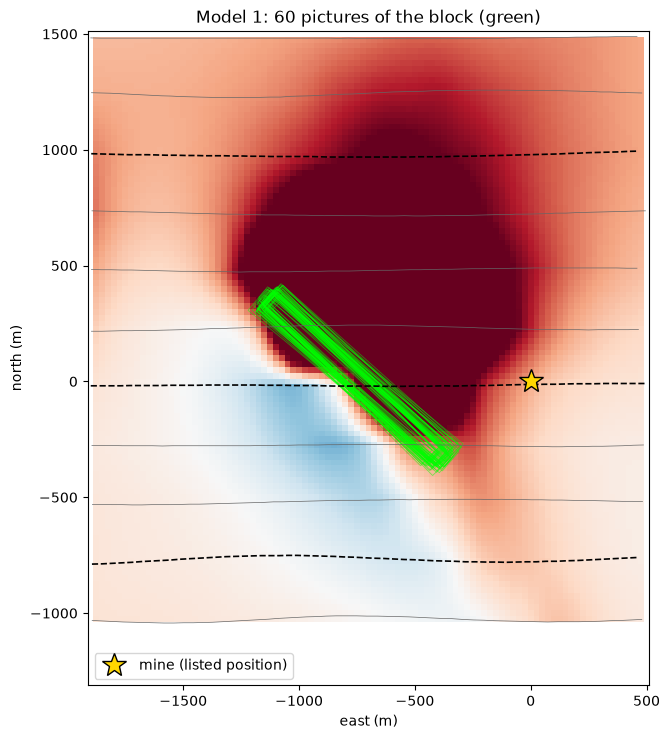

In [6]:
def block_outline(n, e, L, W, s):
    a = np.array([np.cos(s), np.sin(s)]); b = np.array([-np.sin(s), np.cos(s)])
    c = np.array([n, e])
    corners = [c + sa * L / 2 * a + sb * W / 2 * b for sa, sb in [(1, 1), (1, -1), (-1, -1), (-1, 1)]]
    return np.array([[p[1], p[0]] for p in corners])  # (east, north) for plotting

def draw_blocks(ax, theta, n_blocks, n_draw=60, colors=("lime", "magenta", "cyan")):
    p = ob.theta_to_phys(theta[:n_draw], n_blocks)
    for k in range(n_blocks):
        for i in range(min(n_draw, len(theta))):
            poly = block_outline(p["xc"][i, k].item(), p["yc"][i, k].item(), p["length"][i, k].item(),
                                 p["width"][i, k].item(), p["strike"][i, k].item())
            ax.add_patch(Polygon(poly, closed=True, fill=False, ec=colors[k], lw=0.6, alpha=0.5))

fig, ax = plt.subplots(figsize=(8, 8.5))
base_map(ax, "Model 1: 60 pictures of the block (green)")
draw_blocks(ax, theta1, 1); ax.legend(loc="lower left"); plt.show()

### Does it fit? Data vs. the pictures' predictions, line by line
The orange band is the 90% range of what the pictures predict **including the learned misfit level σ** — i.e. where the model says new readings should fall.

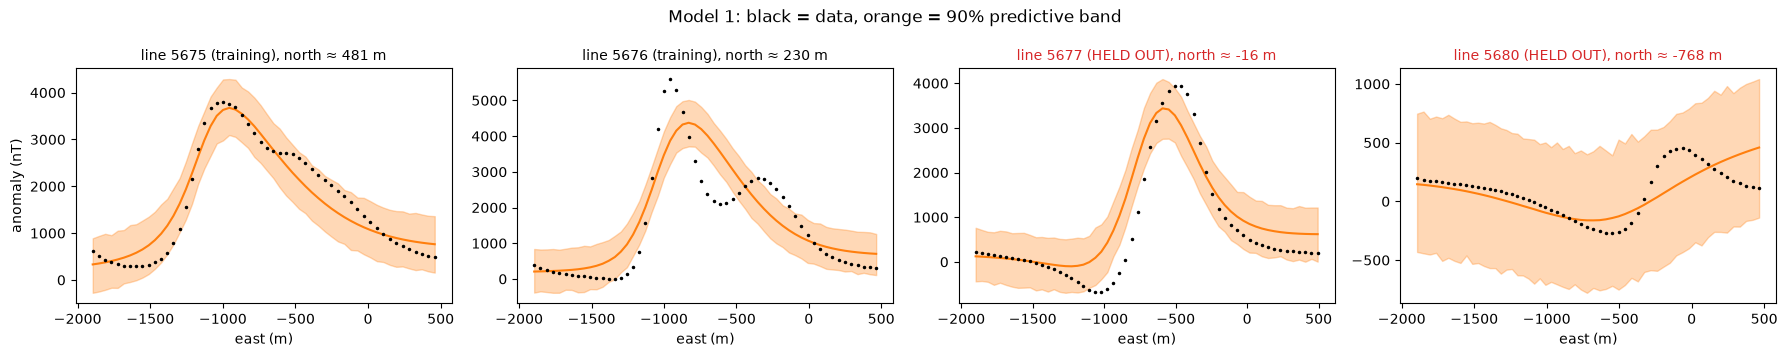

In [7]:
SHOW_LINES = [5675, 5676, 5677, 5680]

def predictive(theta, n_blocks, xyz, n=1000):
    with torch.no_grad():
        mean_pred = ob.predict(theta[:n].to(DEV), n_blocks, *[v.to(DEV) for v in xyz]).cpu()
        sigma = ob.theta_to_phys(theta[:n], n_blocks)["sigma"]
    sim = mean_pred + sigma[:, None] * torch.randn(mean_pred.shape, generator=torch.Generator().manual_seed(0))
    return mean_pred, sim

def plot_lines(theta, n_blocks, title):
    xyz = (T(w.north), T(w.east), T(w.z))
    mean_pred, sim = predictive(theta, n_blocks, xyz)
    lo, hi = np.percentile(sim.numpy(), [5, 95], axis=0); mid = mean_pred.mean(0).numpy()
    fig, axes = plt.subplots(1, len(SHOW_LINES), figsize=(18, 3.6))
    for a, ln in zip(axes, SHOW_LINES):
        m = (w.flight_line == ln).values
        a.fill_between(w.east[m], lo[m], hi[m], color="C1", alpha=0.3)
        a.plot(w.east[m], mid[m], color="C1")
        a.plot(w.east[m], w.total_field_anomaly_nt[m], "k.", ms=3)
        held = ln in ob.HOLDOUT_LINES
        a.set_title(f"line {ln} ({'HELD OUT' if held else 'training'}), north ≈ {w.north[m].mean():.0f} m",
                    color="C3" if held else "k", fontsize=10)
        a.set_xlabel("east (m)")
    axes[0].set_ylabel("anomaly (nT)"); fig.suptitle(title); plt.tight_layout(); plt.show()

plot_lines(theta1, 1, "Model 1: black = data, orange = 90% predictive band")

One block gets the broad shape but misses the **double peaks** (e.g. line 5676 has two humps) — and the learned misfit level σ ≈ 360 nT says so loudly.
On the bright side, the wide band means the model is *honest* about being crude.

## 4. Model 2 — two blocks

In [8]:
post2, flow2, losses2, map2 = fit_model(2, n_iter=3000)
theta2, ess2, tab2 = summarise(post2, flow2, 2)
print(f"importance ESS: {ess2:.0%}")
tab2.quantile([0.05, 0.5, 0.95]).T.round(1)

best fit found; 4 of 64 random starts reached it (within 5 log-units)  [124s]


  step   500  loss   2521.46   [201s]


  step  1000  loss   2516.39   [275s]


  step  1500  loss   2515.25   [349s]


  step  2000  loss   2514.86   [423s]


  step  2500  loss   2514.39   [497s]


  step  3000  loss   2514.24   [571s]


importance ESS: 8%


,0.05,0.50,0.95
B1 north (m),177.4,190.6,201.5
B1 east (m),-997.7,-990.9,-983.8
B1 top (m),30.6,48.4,66.4
B1 bottom (m),371.1,520.9,759.3
B1 length (m),371.8,405.9,442.6
B1 width (m),50.4,98.8,144.7
B1 strike (deg),133.3,138.5,144.0
B1 chi (SI),0.9,1.6,3.5
B2 north (m),30.8,46.4,60.3
B2 east (m),-504.7,-487.8,-471.1


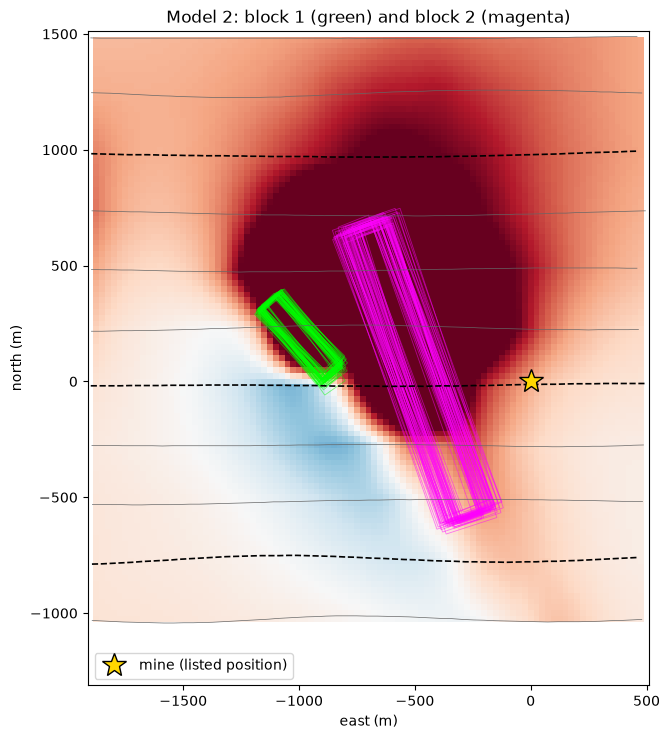

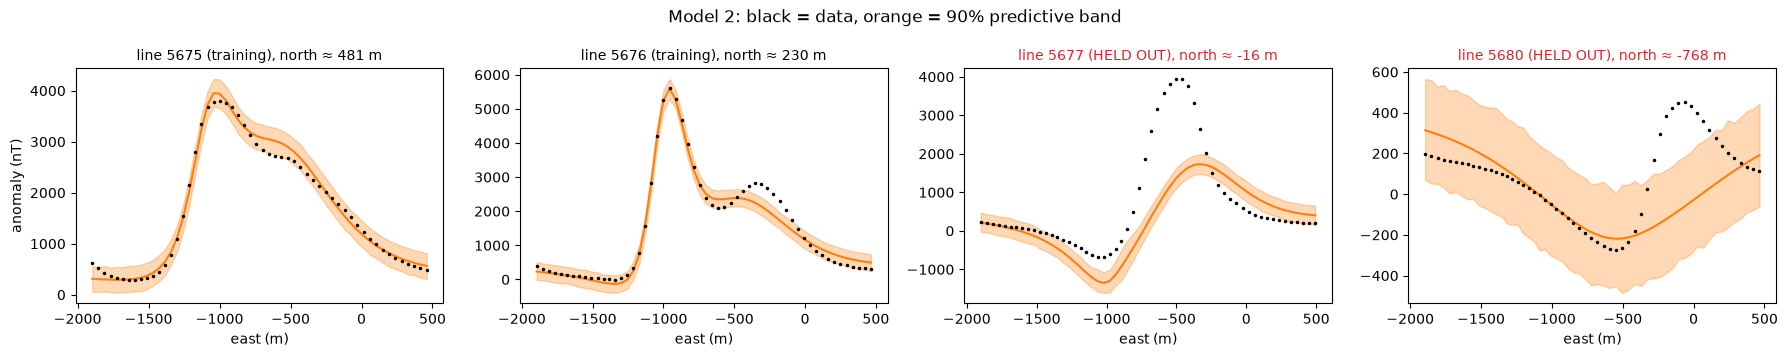

In [9]:
fig, ax = plt.subplots(figsize=(8, 8.5))
base_map(ax, "Model 2: block 1 (green) and block 2 (magenta)")
draw_blocks(ax, theta2, 2); ax.legend(loc="lower left"); plt.show()
plot_lines(theta2, 2, "Model 2: black = data, orange = 90% predictive band")

## 5. Which model should we believe?

Three ways to score each model:
- **misfit level σ** on the training lines (smaller = fits what it saw better);
- **held-out error**: how far the average prediction is from the 3 lines it never saw;
- **held-out honesty**: what fraction of held-out readings fall inside the 90% predictive band (should be ≈ 90%).

In [10]:
def held_out_scores(theta, n_blocks):
    mean_pred, sim = predictive(theta, n_blocks, ho_xyz)
    lo, hi = torch.quantile(sim, 0.05, dim=0), torch.quantile(sim, 0.95, dim=0)
    rms = (mean_pred.mean(0) - ho_y).pow(2).mean().sqrt().item()
    cover = ((ho_y >= lo) & (ho_y <= hi)).double().mean().item()
    return rms, cover

rows = []
for name, theta, K, ess in [("1 block", theta1, 1, ess1), ("2 blocks", theta2, 2, ess2)]:
    rms, cover = held_out_scores(theta, K)
    sigma = ob.theta_to_phys(theta, K)["sigma"].median().item()
    rows.append(dict(model=name, **{"misfit level σ, training (nT)": sigma, "held-out error (nT RMS)": rms,
                                     "held-out readings inside 90% band": cover, "importance ESS": ess}))
scores = pd.DataFrame(rows).set_index("model")
scores.round(2)

,"misfit level σ, training (nT)",held-out error (nT RMS),held-out readings inside 90% band,importance ESS
model,,,,
1 block,361.65,363.06,0.92,0.64
2 blocks,152.09,602.69,0.67,0.08


**This is the most important result of the lesson.**
- Two blocks fit the training lines much better (σ drops from ~360 to ~150 nT)…
- …but predict the held-out lines **worse**, and their 90% bands contain far fewer than 90% of the held-out readings — **overconfident**.

Why? The held-out line 5677 runs right across the main peak, in a 500 m gap between training lines. Model 2 tuned itself to the training lines,
and its σ (one number for the whole survey) is too small for the peak, where a two-block cartoon is most wrong.
Model 1 is cruder, but its huge σ keeps it honest.

This is exactly the overfitting/overconfidence trap from the conversation — and **only the held-out lines revealed it**. The training fit alone would have picked Model 2.

The importance ESS tells a second story: the flow for Model 2 is only a rough match to its posterior (a 22-number posterior with tight, tilted ridges is hard).
On a real job you'd train longer, or reweight samples by `p/q`.

## 6. Check against the published geology

In [11]:
q2 = tab2.quantile([0.05, 0.5, 0.95])
q1 = tab1.quantile([0.05, 0.5, 0.95])
fmt = lambda q, col: f"{q.loc[0.5, col]:.0f} m  ({q.loc[0.05, col]:.0f}–{q.loc[0.95, col]:.0f})"
dist1 = np.hypot(tab1["north (m)"], tab1["east (m)"]).median()
dist2 = np.hypot(tab2["B1 north (m)"], tab2["B1 east (m)"]).median()
facts = pd.DataFrame([
    ("Depth to top of magnetic rock", "25–40 m of cover, ore right below", fmt(q1, "top (m)"), fmt(q2, "B1 top (m)") + " (B1)"),
    ("Length of main ironstone/ore body", "~1100 m (No. 1), ~700 m (No. 2); Cu-Au along 1.3 km", fmt(q1, "length (m)"),
     fmt(q2, "B2 length (m)") + " (B2), " + fmt(q2, "B1 length (m)") + " (B1)"),
    ("Number of main bodies", "two dominant mineralised bodies", "1 (by construction)", "2 (by construction)"),
    ("Distance from listed mine position", "anomaly known to be offset from ore (self-demagnetisation)",
     f"{dist1:.0f} m", f"{dist2:.0f} m (B1)"),
], columns=["quantity", "published", "Model 1 (median, 90%)", "Model 2 (median, 90%)"]).set_index("quantity")
facts

,published,"Model 1 (median, 90%)","Model 2 (median, 90%)"
quantity,,,
Depth to top of magnetic rock,"25–40 m of cover, ore right below",167 m (140–197),48 m (31–66) (B1)
Length of main ironstone/ore body,"~1100 m (No. 1), ~700 m (No. 2); Cu-Au along 1...",1012 m (957–1066),"1328 m (1287–1369) (B2), 406 m (372–443) (B1)"
Number of main bodies,two dominant mineralised bodies,1 (by construction),2 (by construction)
Distance from listed mine position,anomaly known to be offset from ore (self-dema...,760 m,1009 m (B1)


**Reading the table**
- Model 2's western block (B1) puts the top of the magnetic rock at roughly the published base of cover — Model 1's single block is far too deep
  (one block has to be deep and smooth to cover two humps).
- Model 2's eastern block (B2) is ~1.3 km long — the published strike length of the mineralised ironstones. But B2's *top* is ~400+ m deep,
  which contradicts the shallow ore: B2 is probably standing in for several things at once.
- Both models put the magnetic bodies 0.5–1 km from the mine's listed position. Two honest explanations, which we **can't** separate with this data:
  the listed coordinate may mark the mine site rather than the ore body, and the published self-demagnetisation offset is real.
  Our physics ignores self-demagnetisation, so we should *expect* our blocks to be shifted from the true ironstones.

### What we can and can't conclude
- ✅ The anomaly comes from strongly magnetic rock (susceptibility of order 1 SI — magnetite-rich ironstone) starting near the base of the cover.
- ✅ Two-plus bodies, roughly NW–SE trending, about a kilometre long.
- ⚠️ Exact positions and depths of individual bodies: model-dependent. The flow's uncertainty ranges are **conditional on the model being right** —
  and the held-out test shows Model 2 isn't right enough to trust its tight ranges.
- ❌ Where the copper is. Magnetics sees magnetite. Recall the 97 holes drilled into this anomaly before the discovery hole.

## Report card
These checks are about *software and method* sanity; the scientific findings above are printed, not asserted.

In [12]:
results = {
    "block formula matches brute force (< 1e-3)": rel_err < 1e-3,
    "Model 1 flow is a decent posterior match (ESS > 30%)": ess1 > 0.30,
    "Model 2 flow produced usable samples (ESS > 2%)": ess2 > 0.02,
    "all flow samples are finite": bool(torch.isfinite(theta1).all() and torch.isfinite(theta2).all()),
}
for k, v in results.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(results.values()), "some checks failed"

# Save the pictures for Lesson 5
torch.save({"theta1": theta1, "theta2": theta2, "scores": scores.to_dict()}, MODEL_DIR / "lesson04_pictures.pt")

PASS  block formula matches brute force (< 1e-3)
PASS  Model 1 flow is a decent posterior match (ESS > 30%)
PASS  Model 2 flow produced usable samples (ESS > 2%)
PASS  all flow samples are finite


## Take-aways
- Real data needed four upgrades over the textbook version: better physics (blocks), a regional background, a **learned** misfit level, and a warm start.
- The flow did its job — pictures plus uncertainty — but **uncertainty ranges are only as trustworthy as the model**.
- Held-out data is the reality check: the model that fit best was the most overconfident.
- Published geology gave partial agreement (depth to top, strike length) and one clear limitation (self-demagnetisation).

**Things to try:** set `RETRAIN = True` and train Model 2 for 6000 steps — does ESS improve? Move line 5677 into `TRAIN_LINES` (in `osborne.py`) and hold out 5674 instead.

**Next lesson:** turn the pictures into a drilling decision — and see how much the choice of model matters.